[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jeremydwong/bonelab_inverse_dynamics/blob/main/notebooks/tutorial_6dof.ipynb)

# Squat-to-stand with a sliding knee: the evidence for reporting 6-DoF joint power

> **Why you can trust this page:** like the squat-to-stand before it, the
> idealized subject goes through the *exact same pipeline* we use on real
> people: the same calls, copied cell for cell from the Asics running
> notebook. So if the joint powers come out right here, that should give us
> significant confidence in the joint powers we report for a real runner.

We are going to demonstrate the following key steps in the inverse dynamics workflow:

1. Record the same idealized squat as before, except the femur now slides
   forward on the tibia by up to 1 cm (sections 2 and 3).
2. Run it through the Asics pipeline, unchanged: static calibration, chain,
   inverse dynamics, energy audit (section 4).
3. Check the knee's translational power against the truth (section 5).
4. Drop the translational term and watch the energy audit stop closing
   (section 6).
5. Move the knee centre 2 cm and see which joint power moves with it
   (section 7).

This notebook reports on the following key findings about our reanalysis:

1. The pipeline recovers the sliding knee's translational work: 3.214 J
   against a true 3.213 J, with the power never more than 0.008 W off. (That's
   small next to its 246.39 J of rotational work, because 1 cm is small.)
2. The energy audit only closes with it: peak imbalance 0.010 W with 6-DoF
   joint power, 12.70 W with 3-DoF, against 588 W peak dE/dt.
3. Describing the knee wrench 2 cm in front of the knee centre changes the
   knee torque by up to 10.13 N m and 3-DoF knee work from 246.39 J to
   267.63 J. 6-DoF knee work is 249.6 J both ways.

Chapter 2, second page. Previous: [squat-to-stand](tutorial_s2s_markers.ipynb).
Next: the [ten-step quickstart](quickstart_report.ipynb) on real walking data.

### Why a knee that slides

The squat-to-stand used perfect hinges: the thigh and shank always met at
exactly one point. Real knees aren't like that. The femur rolls and slides on
the tibia, and on top of that our joint centres are estimates (a midpoint of
two skin markers, a regression for the hip), so the two segments never agree
exactly on where "the knee" is. When two segments move relative to each other
at the joint, the joint force does work too, not just the joint torque:

$$P_\text{joint} = \underbrace{\boldsymbol\tau\cdot(\boldsymbol\omega_\text{dist}-\boldsymbol\omega_\text{prox})}_{\text{rotational (3-DoF)}}
\;+\; \underbrace{\mathbf F\cdot(\mathbf v_\text{dist}(p)-\mathbf v_\text{prox}(p))}_{\text{translational}}$$

where $\mathbf v_\text{dist}(p)$ is the velocity of the joint point $p$ as a
point on the distal segment, and likewise for the proximal one. Most people
report only the first term (3-DoF). We report the sum (6-DoF), following
Zelik, Takahashi & Sawicki (2015). This page is why, on a body where the
answer is known.

Same person as before (de Leva right leg, pelvis, torso of an 80 kg body,
torso markers on), same squat, plus the slide. What the loader, calibration
and chain are doing is explained step by step in the
[squat-to-stand](tutorial_s2s_markers.ipynb); I don't repeat it here.

In [1]:
# Colab bootstrap — a no-op when running locally in the uv environment.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "boneid @ git+https://github.com/jeremydwong/bonelab_inverse_dynamics"],
                   check=True)
os.makedirs("../reports", exist_ok=True)

## 1 — Import the analysis tools

In [2]:
from pathlib import Path
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

from boneid.core import AnalysisParams, energy_audit, inverse_dynamics
from boneid.io_c3d import build_chain, calibrate_static, load_c3d
from boneid.report import c3d_report_html, c3d_viewer_html, right_step_events

# The report module selects Agg for file rendering; restore notebook figure output.
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
print(f"Repository: {ROOT}")

from boneid.simulate import simulate_squat_to_stand_c3d

Repository: /Users/jeremy/Git/brent/bonelab_inverse_dynamics


## 2 — Choose the study settings

Same as the squat-to-stand, plus how far the knee slides (1 cm).

In [3]:
DATA_DIR = ROOT / "data" / "simulated"
SUBJECT = "SIM"
CONDITION = "S2SSLIP"
TRIAL = "RISE"
SEX = "male"
BODY_MASS_KG = 80.0             # the whole person, as from a scale
CONTACT_THRESHOLD_N = 50.0
KINEMATIC_LOWPASS_HZ = 12.0
TREADMILL_ORIGIN = np.zeros(3)

TORSO_SWAY_RAD = 0.25           # simulator only: makes the motion 3-D
KNEE_SLIP_M = 0.01              # simulator only: femur slides up to 1 cm on the tibia

## 3 — Record the idealized subject, with a knee that slides

`truth` now also holds the true rotational and translational joint powers,
computed from the true motion (not from the pipeline).

In [4]:
truth = simulate_squat_to_stand_c3d(DATA_DIR, subject=SUBJECT, condition=CONDITION,
                                    trial=TRIAL, body_mass=BODY_MASS_KG, sex=SEX,
                                    torso_sway=TORSO_SWAY_RAD, knee_slip_m=KNEE_SLIP_M)
print(truth["dynamic_path"])

/Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/simulated/SIM_S2SSLIP_RISE.c3d


## 4 — Run the Asics pipeline, unchanged

These are the Asics notebook's cells, one after another: load the standing
trial, calibrate, load the squat, set the parameters, build the chain, solve,
audit. The interior energy imbalance at the end (0.0048 W RMS) says the
books already close; the next two sections say why that needs the knee's
translational term.

In [5]:
static = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_Static.c3d")
display({"type": type(static).__name__, "motion_frames": len(static.t),
         "motion_rate_hz": static.rate, "analog_rate_hz": static.analog_rate,
         "marker_count": len(static.markers), "force_shape_Ta_P_xyz": static.force.shape})

{'type': 'C3dTrial',
 'motion_frames': 300,
 'motion_rate_hz': 300.0,
 'analog_rate_hz': 3000.0,
 'marker_count': 28,
 'force_shape_Ta_P_xyz': (3000, 1, 3)}

In [6]:
cal = calibrate_static(static, sex=SEX, body_mass=BODY_MASS_KG)
display({"type": type(cal).__name__, "side": cal.side,
         "body_mass_kg": cal.body_mass, "segment_lengths_m": cal.lengths,
         "joint_centers_and_endpoints_m": cal.points})

{'type': 'StaticCalibration',
 'side': 'r',
 'body_mass_kg': 80.0,
 'segment_lengths_m': {'foot': 0.260000000000001,
  'shank': 0.43000000402659233,
  'thigh': 0.4499999701642309,
  'pelvis': 0.11000002664016757,
  'forefoot_width': 0.07000000000000024,
  'torso': 0.4999999753634077},
 'joint_centers_and_endpoints_m': {'ankle': array([-0.064,  0.   ,  0.08 ]),
  'knee': array([-0.064     , -0.01289806,  0.50980652]),
  'hip': array([-6.40000000e-02,  5.99910021e-04,  9.59604004e-01]),
  'hip_l': array([6.40000000e-02, 5.99910021e-04, 9.59604004e-01]),
  'mid_hip': array([0.00000000e+00, 5.99910021e-04, 9.59604004e-01]),
  'l5s1': array([ 0.        , -0.00159995,  1.06958203]),
  'heel': array([-0.064,  0.06 ,  0.03 ]),
  'toe': array([-0.064, -0.13 ,  0.02 ]),
  'toebox': array([-0.064, -0.2  ,  0.03 ]),
  'mid_acromion': array([ 0.        , -0.00659986,  1.56955701])}}

In [7]:
trial = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_{TRIAL}.c3d")
display({"type": type(trial).__name__, "motion_frames": len(trial.t),
         "motion_rate_hz": trial.rate, "analog_rate_hz": trial.analog_rate,
         "force_shape_Ta_P_xyz": trial.force.shape,
         "marker_names": sorted(trial.markers)})  

{'type': 'C3dTrial',
 'motion_frames': 900,
 'motion_rate_hz': 300.0,
 'analog_rate_hz': 3000.0,
 'force_shape_Ta_P_xyz': (9000, 1, 3),
 'marker_names': ['AnkleLat',
  'C7',
  'CLAV',
  'DorsalFoot',
  'HeelLat',
  'HeelMed',
  'KneeLat',
  'LAC',
  'LASIS',
  'LGT',
  'LPSIS',
  'MTP1Head',
  'MTP5Head',
  'RAC',
  'RASIS',
  'RGT',
  'RPSIS',
  'STRN',
  'ShankAntProx',
  'ShankPostDist',
  'ShankPostProx',
  'T10',
  'ThighAntProx',
  'ThighPostDist',
  'ThighPostProx',
  'ToeboxAnt']}

In [8]:
params = AnalysisParams(contact_threshold_n=CONTACT_THRESHOLD_N,
                        lowpass_hz=KINEMATIC_LOWPASS_HZ,
                        force_lowpass_hz=KINEMATIC_LOWPASS_HZ)
display(params)

AnalysisParams(gravity=array([ 0.  ,  0.  , -9.81]), contact_threshold_n=50.0, lowpass_hz=12.0, force_lowpass_hz=12.0, filter_order=4, treadmill_speed=0.0, flag_crossover=False)

In [9]:
skeleton, kin, ground, quality = build_chain(
    trial, cal, point=TREADMILL_ORIGIN, threshold_n=CONTACT_THRESHOLD_N)
display({"segments": skeleton.segment_names, "joints": skeleton.joint_names,
         "segment_mass_kg": skeleton.mass, "segment_length_m": skeleton.length,
         "kin_r_world_shape_T_S_3_3": kin.r_world.shape,
         "ground_force_shape_T_xyz": ground.force.shape,
         "ground_moment_shape_T_xyz": ground.moment.shape,
         "quality_fields": list(quality)})

{'segments': ['foot', 'shank', 'thigh', 'pelvis', 'torso'],
 'joints': ['ankle', 'knee', 'hip', 'l5s1'],
 'segment_mass_kg': array([ 1.096,  3.464, 11.328,  8.936, 31.384]),
 'segment_length_m': array([0.26      , 0.43      , 0.44999997, 0.11000003, 0.49999998]),
 'kin_r_world_shape_T_S_3_3': (900, 5, 3, 3),
 'ground_force_shape_T_xyz': (900, 3),
 'ground_moment_shape_T_xyz': (900, 3),
 'quality_fields': ['cluster_residual', 'bouts', 'points']}

In [10]:
idres = inverse_dynamics(skeleton, kin, ground, params)
display({"type": type(idres).__name__,
         "joint_force_shape_T_J_xyz_N": idres.joint_force.shape,
         "joint_torque_shape_T_J_xyz_Nm": idres.joint_torque.shape,
         "residual_force_shape_T_xyz_N": idres.residual_force.shape})

{'type': 'InverseDynamicsResult',
 'joint_force_shape_T_J_xyz_N': (900, 4, 3),
 'joint_torque_shape_T_J_xyz_Nm': (900, 4, 3),
 'residual_force_shape_T_xyz_N': (900, 3)}

In [11]:
audit = energy_audit(skeleton, kin, ground, idres, params)
edge = slice(int(kin.rate), -int(kin.rate))
display({"type": type(audit).__name__, "energy_shape_T": audit.kinetic.shape,
         "joint_power_shape_T_J": audit.joint_power.shape,
         "interior_imbalance_rms_W": float(np.sqrt(np.mean(audit.imbalance[edge] ** 2))),
         "interior_imbalance_peak_abs_W": float(np.max(np.abs(audit.imbalance[edge])))})

{'type': 'EnergyAudit',
 'energy_shape_T': (900,),
 'joint_power_shape_T_J': (900, 4),
 'interior_imbalance_rms_W': 0.004820874237598885,
 'interior_imbalance_peak_abs_W': 0.010200911959202585}

## 5 — Check the knee's translational power against the truth

Solid lines are the pipeline, dashed are the truth. Left: the knee's
rotational power. Right: its translational power, which is zero for a perfect
hinge and here isn't.

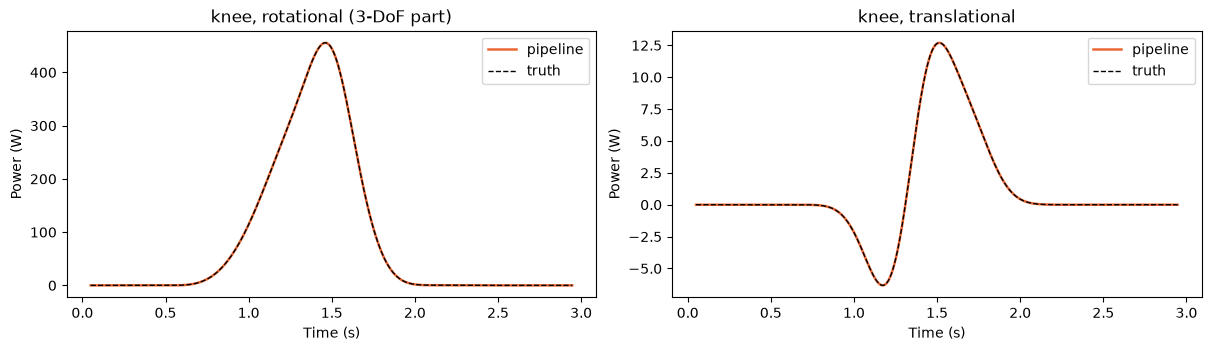

{'ankle': {'translational work, truth (J)': -0.0,
  'translational work, pipeline (J)': -0.0,
  'rotational work, pipeline (J)': -17.37,
  'max |translational power error| (W)': 0.0014642397502848457},
 'knee': {'translational work, truth (J)': 3.213,
  'translational work, pipeline (J)': 3.214,
  'rotational work, pipeline (J)': 246.39,
  'max |translational power error| (W)': 0.007996626398383277},
 'hip': {'translational work, truth (J)': 0.0,
  'translational work, pipeline (J)': 0.001,
  'rotational work, pipeline (J)': 98.34,
  'max |translational power error| (W)': 0.001983384266626294},
 'l5s1': {'translational work, truth (J)': -0.0,
  'translational work, pipeline (J)': -0.0,
  'rotational work, pipeline (J)': 22.15,
  'max |translational power error| (W)': 0.013410372794375833}}

In [12]:
from boneid.report import JOINT_COLORS

inner = slice(15, -15)
t = idres.t
knee = skeleton.joint_names.index("knee")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained")
for ax, pipe, true, title in (
        (axes[0], audit.joint_power_rotational, truth["joint_power_rotational"], "knee, rotational (3-DoF part)"),
        (axes[1], audit.joint_power_translational, truth["joint_power_translational"], "knee, translational")):
    ax.plot(t[inner], pipe[inner, knee], color=JOINT_COLORS[1], lw=1.8, label="pipeline")
    ax.plot(t[inner], true[inner, knee], color="k", lw=1.0, ls="--", label="truth")
    ax.set(xlabel="Time (s)", ylabel="Power (W)", title=title)
    ax.legend()
plt.show()

dt = 1.0 / kin.rate
def work(p):
    return float(p[inner].sum() * dt)
display({name: {"translational work, truth (J)": round(work(truth["joint_power_translational"][:, j]), 3),
                "translational work, pipeline (J)": round(work(audit.joint_power_translational[:, j]), 3),
                "rotational work, pipeline (J)": round(work(audit.joint_power_rotational[:, j]), 2),
                "max |translational power error| (W)": float(np.abs(audit.joint_power_translational[inner, j]
                                                              - truth["joint_power_translational"][inner, j]).max())}
         for j, name in enumerate(skeleton.joint_names)})

Only the knee slides, so only the knee has translational power, and the
pipeline gets it right to within 0.008 W. It's small here (3.2 J against
~246 J of rotational work) because 1 cm is small. But it isn't zero, and the
next section shows why that matters.

## 6 — Drop the translational term: the energy audit stops closing

The energy audit compares the change in the body's energy with the power
going in. `energy_audit` always keeps both terms. Drop the translational one
(what you'd get from 3-DoF joint power) and the books stop balancing, by
exactly the power the sliding knee does.

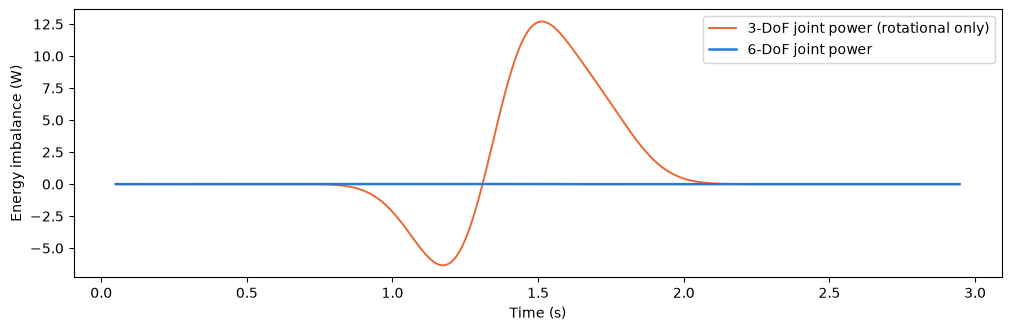

peak |imbalance|: 6-DoF 0.010 W, 3-DoF 12.70 W, of 588 W peak dE/dt


In [13]:
imb_6 = audit.imbalance
imb_3 = audit.imbalance + audit.joint_power_translational.sum(axis=1)   # translational term removed
fig, ax = plt.subplots(figsize=(10, 3.2), layout="constrained")
ax.plot(t[inner], imb_3[inner], color=JOINT_COLORS[1], lw=1.4, label="3-DoF joint power (rotational only)")
ax.plot(t[inner], imb_6[inner], color=JOINT_COLORS[0], lw=1.8, label="6-DoF joint power")
ax.set(xlabel="Time (s)", ylabel="Energy imbalance (W)")
ax.legend()
plt.show()
print(f"peak |imbalance|: 6-DoF {np.abs(imb_6[inner]).max():.3f} W, "
      f"3-DoF {np.abs(imb_3[inner]).max():.2f} W, of {np.abs(audit.de_dt).max():.0f} W peak dE/dt")

## 7 — Move the knee centre 2 cm: 3-DoF power moves, 6-DoF doesn't

This is the part I find most convincing. On a real person we never know
exactly where the knee centre is. Say we're off by 2 cm, forward. The wrench
the thigh puts on the shank is the same physical thing no matter where we
choose to describe it, but its *torque* depends on the point:
$\boldsymbol\tau' = \boldsymbol\tau - (p'-p)\times\mathbf F$. So the
torque changes, the rotational power changes, and a 3-DoF analysis gives a
different answer. The translational term changes by exactly the opposite
amount, so the 6-DoF sum doesn't move.

Below I take the pipeline's knee wrench and velocities and re-express them
about a point 2 cm in front of the knee (along the shank's forward axis).

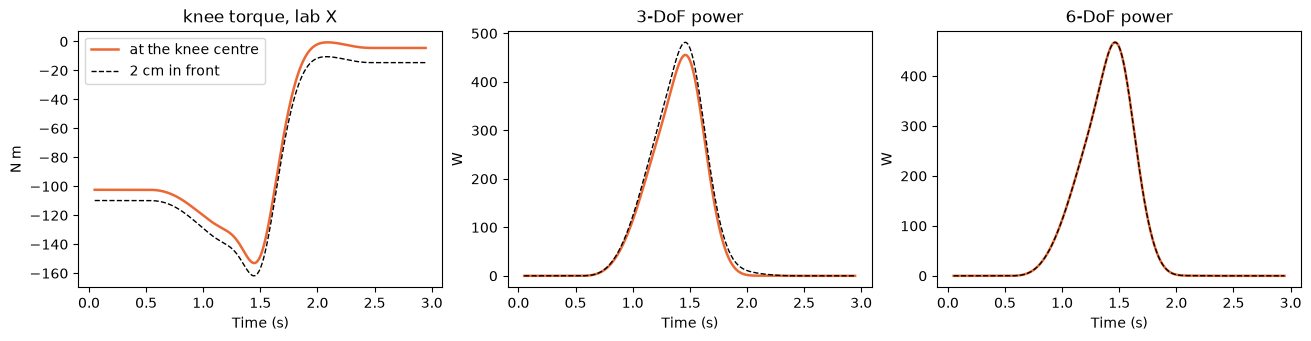

{'max change in knee torque (N m)': 10.128790441074523,
 'max change in 3-DoF power (W)': 26.208536630909805,
 'max change in 6-DoF power (W)': 1.7053025658242404e-13,
 '3-DoF work, centre vs 2 cm (J)': (246.39, 267.63),
 '6-DoF work, centre vs 2 cm (J)': (249.6, 249.6)}

In [14]:
from boneid.core import chain_kinematics

ck = chain_kinematics(skeleton, kin, params.lowpass_hz, params.filter_order)

def knee_powers(offset_m):
    """(torque, rotational, translational) power at the knee, with the wrench
    expressed about a point `offset_m` in front of the knee centre."""
    d, p = knee, knee + 1                       # distal = shank, proximal = thigh
    point = ck["prox"][:, d] + offset_m * ck["r"][:, d, :, 0]
    F = idres.joint_force[:, d]
    tau = idres.joint_torque[:, d] - np.cross(point - ck["prox"][:, d], F)
    on_d = ck["v_com"][:, d] + np.cross(ck["omega"][:, d], point - ck["com"][:, d])
    on_p = ck["v_com"][:, p] + np.cross(ck["omega"][:, p], point - ck["com"][:, p])
    rot = np.sum(tau * (ck["omega"][:, d] - ck["omega"][:, p]), axis=1)
    tr = np.sum(F * (on_d - on_p), axis=1)
    return tau, rot, tr

tau0, rot0, tr0 = knee_powers(0.0)
tau2, rot2, tr2 = knee_powers(0.02)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), layout="constrained")
for ax, a, b, title, unit in ((axes[0], tau0[:, 0], tau2[:, 0], "knee torque, lab X", "N m"),
                              (axes[1], rot0, rot2, "3-DoF power", "W"),
                              (axes[2], rot0 + tr0, rot2 + tr2, "6-DoF power", "W")):
    ax.plot(t[inner], a[inner], color=JOINT_COLORS[1], lw=1.8, label="at the knee centre")
    ax.plot(t[inner], b[inner], color="k", lw=1.0, ls="--", label="2 cm in front")
    ax.set(xlabel="Time (s)", ylabel=unit, title=title)
axes[0].legend()
plt.show()
display({"max change in knee torque (N m)": float(np.abs(tau2 - tau0)[inner].max()),
         "max change in 3-DoF power (W)": float(np.abs(rot2 - rot0)[inner].max()),
         "max change in 6-DoF power (W)": float(np.abs((rot2 + tr2) - (rot0 + tr0))[inner].max()),
         "3-DoF work, centre vs 2 cm (J)": (round(work(rot0), 2), round(work(rot2), 2)),
         "6-DoF work, centre vs 2 cm (J)": (round(work(rot0 + tr0), 2), round(work(rot2 + tr2), 2))})

## Where this leaves you

The three findings at the top all check out on a body where we know the
answer. The last one is the real reason we report 6-DoF power: on a real
subject the joint centres *are* guesses, so it's nice when the thing you
report doesn't depend on them. Torques still do (10.13 N m for a 2 cm shift
here), so read those with the joint-centre caveat in mind. The same
3-DoF vs 6-DoF comparison on real walking data, every joint of subject P1, is
in the "Joint work: 3-DOF versus 6-DOF" section of the
[P1 report](p1_report.ipynb).

Next: the [ten-step quickstart](quickstart_report.ipynb) on subject P1's
walking data.